# Projeto Integrador – Módulo Analytics
## A expansão solar e a rampa de fim de tarde da carga líquida do SIN (2023–2025)

### Identificação
| Campo | Preenchimento |
|---|---|
| **Nome do participante** | Felipe Souza Barros Damasceno |
| **Título do projeto** | A expansão solar e a rampa de fim de tarde da carga líquida do SIN (2023–2025) |
| **Turma** | Turma ONS |
| **Data de entrega** | 25/11/2026 |

**Como executar:** reinicie o kernel e execute todas as células (*Restart → Run All*). Os arquivos CSV e este notebook ficam na mesma pasta (`Projeto Integrador - Felipe Damasceno/`), e os gráficos são gravados nessa mesma pasta (ou na subpasta configurada). Detalhes no `README.md`.

## 1. Resumo executivo
No fim da tarde (16h→19h), a geração solar se encerra enquanto a carga sobe, e as fontes controláveis precisam assumir essa diferença. O projeto verificou se o crescimento dessa rampa (variação da carga líquida entre 16h e 19h) no SIN entre 2023 e 2025 acompanha o crescimento da carga ou a saída da geração solar.
Com dados horários de 3 anos (2023 a 2025), comparou-se o ritmo de crescimento da carga, da geração solar e da rampa, decompondo a variação vespertina em subida da carga, variação eólica e saída da solar. Ao analisar o agregado nacional (SIN), observou-se que a carga média cresceu apenas 8% e a geração solar cerca de 114%; a rampa média passou de 6,9 para 13,9 GW (+101%) e foi maior em 2025 nos 12 meses. A saída da solar explica praticamente todo o aumento da rampa, enquanto a subida da carga no fim de tarde (+1,7 GW) foi compensada pela eólica (−1,8 GW). Recomenda-se dimensionar o recurso controlável do fim de tarde considerando a expansão solar, e não apenas a previsão de carga. Principal limitação: dados horários e geração distribuída embutida na carga, o que tende a subestimar a rampa real.

## 2. Contexto e problema
### 2.1 Contexto
A geração solar foi a fonte que mais cresceu no SIN: a média passou de 4,9 GWmed em 2023 para 10,5 GWmed em 2025. No fim da tarde, essa geração se encerra justamente quando a carga sobe, e a energia que deixa de existir precisa ser reposta, no mesmo intervalo, por hidráulica e térmica.

A **carga líquida** mede a parte da carga que sobra para essas fontes, e a **rampa de fim de tarde** mede quanto ela aumenta entre 16h e 19h:

$$CL = \text{Carga} - \text{Eólica} - \text{Solar} \qquad\qquad \text{Rampa} = CL19h - CL16h$$

O termo carga líquida não possui definição formal no Glossário dos Procedimentos de Rede (Submódulo 1.2, rev. 2025.02); neste trabalho, é a carga verificada menos a geração eólica e solar supervisionadas.

### 2.2 Público e decisão
Programação da operação (pré-operação) e operadores de tempo real do SIN. **Decisão apoiada:** dimensionar o recurso controlável do fim de tarde pela previsão de carga ou pela expansão solar.

| Fenômeno | Recorte | Indicador | Público | Uso |
|---|---|---|---|---|
| Rampa de fim de tarde da carga líquida | SIN, 16h→19h, 2023–2025 | Rampa diária (MW) | Programação e tempo real | Dimensionar o recurso controlável |

### 2.3 Pergunta analítica
> *Como o crescimento da carga e o crescimento da geração solar se relacionam com a rampa da carga líquida no fim de tarde (16h→19h) do SIN entre 2023 e 2025, e qual dos dois deve orientar o dimensionamento do recurso controlável?*

### 2.4 Objetivo e critérios de sucesso
1. Comparar, ano a ano, o crescimento da carga, da geração solar e da rampa de fim de tarde.
2. Dividir o aumento da rampa em subida da carga, variação eólica e saída da solar, com parcelas que fecham exatamente.

### Configuração do ambiente
Todos os caminhos são relativos à pasta do notebook.

In [2]:
import os                                                                                                       # manipulação de caminhos e criação de pastas
import glob                                                                                                     # busca de arquivos por padrão de nome (no nosso caso vamos usar arquivos em csv)
import pandas as pd                                                                                             # leitura e tratamento dos dados em tabelas 
import matplotlib.pyplot as plt                                                                                 # criação dos gráficos
from IPython.display import display                                                                             # exibe tabelas formatadas no notebook

# ===== PARÂMETROS =====
# Como o notebook e os arquivos CSV estão todos juntos na pasta 'Projeto Integrador - Felipe Damasceno',
# usamos '.' para apontar diretamente para a pasta atual do notebook.
PASTA_PROJETO = '.'
PASTA_DADOS = PASTA_PROJETO
PASTA_RESULTADOS = os.path.join(PASTA_PROJETO, 'resultados')
PADRAO_ARQUIVOS = 'BALANCO_ENERGIA_SUBSISTEMA_*.csv'


# Texto de referência da fonte, inserido no rodapé de todos os gráficos.
FONTE = 'Fonte: ONS – Dados Abertos, Balanço de Energia nos Subsistemas (2023–2025)'
# Cor fixa para cada ano, garantindo padronização visual entre os gráficos.
# Tons de azul para 2023 e 2024 e vermelho para destacar 2025 (ano mais recente).
CORES = {2023: '#9DB4D3', 2024: '#4C72B0', 2025: "#C74E52"}

os.makedirs(PASTA_RESULTADOS, exist_ok=True)
pd.set_option('display.float_format', '{:,.1f}'.format)


def salvar(nome):
    # rect=[esquerda, base, direita, topo]: o gráfico ocupa de 3% a 100% da altura,
    # deixando espaço livre no rodapé para o texto da fonte.
    plt.tight_layout(rect=[0, 0.03, 1, 1])  # Insere a fonte dos dados no canto inferior esquerdo da figura.
    plt.figtext(0.01, 0.005, FONTE, fontsize=7)

    # Salva o gráfico na pasta do projeto. bbox_inches='tight' recorta as bordas em branco
    # sem cortar o texto da fonte.
    plt.savefig(os.path.join(PASTA_RESULTADOS, nome), dpi=150, bbox_inches='tight')
  
    plt.show()

## 3. Conjuntos de dados e avaliação dos dados
### 3.1 Juntando os dados
Na base, cada linha corresponde a uma horário e um subsistema (N, NE, S, SE e o agregado SIN), em MWmed, de 01/01/2023 a 31/12/2025. A análise usa apenas o SIN, agregado em uma linha por dia com os valores das 16h e das 19h.

In [20]:
# LEITURA DOS DADOS BRUTOS
# Aqui nos vamos ler o arquivos em CSV e juntar tudo em um dataframe genérico que vamos chamar de df

# os.path.join monta o caminho completo: PASTA_DADOS + nome do arquivo.
# sep=';' indica que as colunas do CSV do ONS são separadas por ponto e vírgula.
df_2023 = pd.read_csv(os.path.join(PASTA_DADOS, 'BALANCO_ENERGIA_SUBSISTEMA_2023.csv'), sep=';')
df_2024 = pd.read_csv(os.path.join(PASTA_DADOS, 'BALANCO_ENERGIA_SUBSISTEMA_2024.csv'), sep=';')
df_2025 = pd.read_csv(os.path.join(PASTA_DADOS, 'BALANCO_ENERGIA_SUBSISTEMA_2025.csv'), sep=';')

# Mostra quantas linhas e colunas cada arquivo tem, para conferência.
print('2023:', df_2023.shape)
print('2024:', df_2024.shape)
print('2025:', df_2025.shape)


# Junção dos 3 anos em um dataframe

# pd.concat empilha os 3 DataFrames, um abaixo do outro.
# ignore_index=True renumera as linhas de 0 até o fim, evitando índices repetidos.
df = pd.concat([df_2023, df_2024, df_2025], ignore_index=True)


# Conferência do resultado 

# Total de linhas e colunas após a junção (linhas = soma dos 3 anos).
print('Total:', df.shape)

# Primeiro e último registro da coluna de data/hora, para confirmar o período.
print('Período:', df['din_instante'].min(), 'a', df['din_instante'].max())

# Exibe as 5 primeiras linhas para inspecionar a estrutura dos dados.
df.head()

2023: (43800, 9)
2024: (43920, 9)
2025: (43800, 9)
Total: (131520, 9)
Período: 2023-01-01 00:00:00 a 2025-12-31 23:00:00


,id_subsistema,nom_subsistema,din_instante,val_gerhidraulica,val_gertermica,val_gereolica,val_gersolar,val_carga,val_intercambio
0,NE,NORDESTE,2023-01-01 00:00:00,"3,874.1",677.1,"13,305.3",1.9,"10,455.8","7,402.5"
1,N,NORTE,2023-01-01 00:00:00,"7,858.7",877.9,211.8,0.0,"5,990.6","2,957.8"
2,SIN,SISTEMA INTERLIGADO NACIONAL,2023-01-01 00:00:00,"39,057.3","5,698.3","14,138.8",21.2,"58,904.1",11.5
3,SE,SUDESTE/CENTRO-OESTE,2023-01-01 00:00:00,"24,661.1","4,071.6",6.0,18.2,"32,183.9","-3,427.0"
4,S,SUL,2023-01-01 00:00:00,"2,663.4",71.8,615.7,1.0,"10,273.8","-6,921.9"


### 3.2 Variáveis utilizadas
| Variável | Tipo | Descrição | Uso na análise |
|---|---|---|---|
| `din_instante` | Data/hora | Data e hora de referência | Ano, mês e hora |
| `val_carga` | Numérica | Carga verificada (MWmed) | Carga líquida e subida da carga |
| `val_gereolica` | Numérica | Geração eólica (MWmed) | Carga líquida |
| `val_gersolar` | Numérica | Geração fotovoltaica (MWmed) | Carga líquida e saída da solar |
| `val_gerhidraulica` / `val_gertermica` | Numérica | Geração hidráulica e térmica | Como a rampa foi suprida |
| `val_intercambio` | Numérica | Intercâmbio líquido (MWmed) | Conferência do balanço |

### 3.3 Limitações e cuidados
A geração distribuída aparece como redução da carga. Não há cortes de geração, reserva ou previsões. Valores horários não capturam rampas dentro da hora. Os dados são públicos e agregados, sem questões de privacidade, e os resultados valem para o SIN no período analisado.

## 4. Preparação dos dados
### 4.1 Primeira verificação
Cada verificação abaixo alimenta uma linha da tabela-resumo ao final desta seção.

**Valores ausentes, duplicidades e tipos**

In [21]:
# 4.1 Valores ausentes, duplicidades e tipos

# Valores ausentes df.isna() marca True onde falta valor e False onde há valor e o 1º .sum() conta os ausentes de cada coluna; o 2º .sum() soma o total da base
print('Valores ausentes:', df.isna().sum().sum())

# Vamos contar as repetidas
# A chave da base é subsistema + instante: cada subsistema deve ter 1 registro por hora. duplicated() marca True nas linhas que repetem essa combinação; .sum() conta quantas são
print('Duplicidades (subsistema + instante):', df.duplicated(['id_subsistema', 'din_instante']).sum())

# Tipo da coluna de data antes da conversão
print('Tipo de din_instante antes da conversão:', df['din_instante'].dtype)

# pd.to_datetime transforma o texto em data/hora e substitui a coluna original
# Depois disso, .dt.year, .dt.month e .dt.hour passam a funcionar nas próximas células
# Se algum texto estiver em formato diferente deve retornar erro
df['din_instante'] = pd.to_datetime(df['din_instante'])

# Tipo depois da conversão
print('Tipo após a conversão:', df['din_instante'].dtype)

# Verificando o número de linhas por subsistema
print('\nHoras por subsistema:')
print(df['id_subsistema'].value_counts())

Valores ausentes: 0
Duplicidades (subsistema + instante): 0
Tipo de din_instante antes da conversão: object
Tipo após a conversão: datetime64[ns]

Horas por subsistema:
id_subsistema
NE     26304
N      26304
SIN    26304
SE     26304
S      26304
Name: count, dtype: int64


In [22]:
# Conferindo se o SIN é mesmo a soma dos 4 subsistemas, (N + NE + S + SE).
# Coloca os subsistemas lado a lado (em colunas) para somá-los hora a hora
carga_sub = df.pivot_table(index='din_instante', columns='id_subsistema', values='val_carga')

# Soma os 4 subsistemas, compara com o valor informado para o SIN e pega a maior diferença encontrada
dif = (carga_sub[['N', 'NE', 'S', 'SE']].sum(axis=1) - carga_sub['SIN']).abs().max()

print(f'Maior diferença entre a carga do SIN e a soma dos 4 subsistemas: {dif:.3f} MW')

Maior diferença entre a carga do SIN e a soma dos 4 subsistemas: 0.005 MW


**0.005** MW é um valor muito pequeno. Acredito que seja devido a algum arredondamento do sistema.

In [23]:
# Checando valores zerados e negativos na base
# Nem todo zero é erro (a geração solar, por exemplo, é zero à noite).
# Vamos investigar onde os zeros aparecem e garantir que não há gerações negativas.

sin_bruto = df[df['id_subsistema'] == 'SIN']
colunas = ['val_carga', 'val_gerhidraulica', 'val_gertermica', 'val_gereolica', 'val_gersolar']

# Conta quantos zeros existem em cada variável do SIN
print('Zeros por coluna (SIN):')
print((sin_bruto[colunas] == 0).sum())

# Lista as horas do dia em que a solar zerou (esperado: apenas período noturno)
print('\nHoras em que a solar do SIN vale zero:')
print(sorted(sin_bruto.loc[sin_bruto['val_gersolar'] == 0, 'din_instante'].dt.hour.unique()))

# Valores negativos de geração não são coerentes
print('Valores negativos de geração:', (df[colunas[1:]] < 0).sum().sum())

Zeros por coluna (SIN):
val_carga              0
val_gerhidraulica      0
val_gertermica         0
val_gereolica          0
val_gersolar         422
dtype: int64

Horas em que a solar do SIN vale zero:
[np.int32(0), np.int32(1), np.int32(2), np.int32(3), np.int32(20), np.int32(21), np.int32(22), np.int32(23)]
Valores negativos de geração: 0


### 4.2 Registro dos tratamentos
| Tratamento realizado | Justificativa | Impacto ou validação |
|---|---|---|
| Conversão de data/hora | Extrair ano, mês e hora | Nenhum valor perdido |
| Filtro do SIN | Evitar dupla contagem | 26.304 horas |
| Cálculo da carga líquida | Variável da pergunta | Definição explícita |
| Agregação diária (16h e 19h) | Unidade de decisão é o dia | 1.096 dias; parcelas fecham com a rampa |

### 4.3 Preparação dos dados
Leitura dos CSVs na pasta do projeto (`Projeto Integrador - Felipe Damasceno/`) → conversão de data/hora → diagnóstico → filtro do SIN → carga líquida → tabela diária com rampa e parcelas → gravação das figuras na mesma pasta.

In [24]:
# 4.3 Preparação dos dados: montando a tabela diária

# 1. Filtra apenas o SIN, encurta os nomes das colunas e calcula a carga líquida
sin = df[df['id_subsistema'] == 'SIN'].rename(columns={
    'val_carga': 'carga', 'val_gereolica': 'eolica', 'val_gersolar': 'solar',
    'val_gerhidraulica': 'hidro', 'val_gertermica': 'termica'
}).copy()

sin['carga_liquida'] = sin['carga'] - sin['eolica'] - sin['solar']

# Desmembra a data e hora para facilitar os filtros e agrupamentos seguintes
sin['ano']  = sin['din_instante'].dt.year
sin['mes']  = sin['din_instante'].dt.month
sin['hora'] = sin['din_instante'].dt.hour
sin['data'] = sin['din_instante'].dt.date

print('Horas do SIN:', len(sin))

# 2. Isola os registros das 16h e das 19h, usando a data para alinhar cada dia
h16 = sin[sin['hora'] == 16].set_index('data')
h19 = sin[sin['hora'] == 19].set_index('data')

# 3. Calcula a variação no fim de tarde (19h − 16h) para a rampa e cada fonte
cols = ['carga_liquida', 'carga', 'eolica', 'solar', 'hidro', 'termica']
dia = h19[cols] - h16[cols]
dia.columns = ['rampa', 'd_carga', 'd_eolica', 'd_solar', 'd_hidro', 'd_termica']
dia[['ano', 'mes']] = h16[['ano', 'mes']]

# 4. Confere o total de dias analisados e mostra uma prévia da tabela final
dias_por_ano = dia['ano'].value_counts().sort_index().to_dict()
print('Dias analisados:', len(dia), '| por ano:', dias_por_ano)

dia.head()

Horas do SIN: 26304
Dias analisados: 1096 | por ano: {2023: 365, 2024: 366, 2025: 365}


,rampa,d_carga,d_eolica,d_solar,d_hidro,d_termica,ano,mes
data,,,,,,,,
2023-01-01,"16,750.8","14,936.6","1,461.5","-3,275.8","16,763.5",-12.7,2023,1
2023-01-02,"5,817.0","4,699.1","1,342.4","-2,460.3","5,862.9",-46.0,2023,1
2023-01-03,"2,616.3","3,288.6","2,119.5","-1,447.2","2,543.6",79.4,2023,1
2023-01-04,"5,470.4","4,007.2",684.1,"-2,147.4","5,413.9",63.3,2023,1
2023-01-05,"6,470.0","4,805.1",25.7,"-1,690.5","6,428.1",41.8,2023,1


## 5. Análise exploratória
### 5.1 Estratégia e visualizações principais

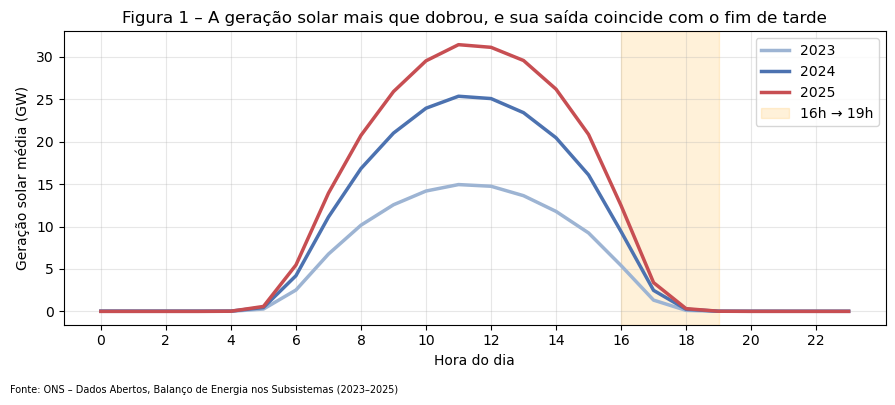

In [25]:
# Calcula a geração solar média (em GW, por isso dividimos 1000) para cada hora do dia, separada por ano
solar_hora = sin.pivot_table(index='hora', columns='ano', values='solar') / 1000

# Monta o gráfico do perfil horário da geração solar
plt.figure(figsize=(9, 4))
for ano, cor in CORES.items():
    plt.plot(solar_hora.index, solar_hora[ano], color=cor, lw=2.5, label=ano)

# Destaca a janela do fim de tarde e ajusta títulos, eixos e grade
plt.axvspan(16, 19, color='orange', alpha=0.15, label='16h → 19h')
plt.title('Figura 1 – A geração solar mais que dobrou, e sua saída coincide com o fim de tarde')
plt.xlabel('Hora do dia')
plt.ylabel('Geração solar média (GW)')
plt.xticks(range(0, 24, 2))
plt.legend()
plt.grid(alpha=0.3)

# Ajusta o espaço, coloca a fonte no rodapé e apenas exibe na tela
salvar('fig1_solar.png')

**Resultado observado:** o pico solar ao meio-dia cresce ano a ano, e a geração cai a quase zero entre 16h e 19h.  
**Limitação:** apenas a solar supervisionada; a geração distribuída não aparece separada.

In [26]:
# Calcula as médias anuais (carga, solar e rampa) e a rampa média mensal (em MW)
medias = sin.groupby('ano')[['carga', 'solar']].mean()
medias['rampa'] = dia.groupby('ano')['rampa'].mean()
rampa_mes = dia.pivot_table(index='mes', columns='ano', values='rampa')

# Exibe os dois resumos em GW para facilitar a leitura
print('Médias anuais (GW):')
display(medias / 1000)

print('\nRampa média por mês (GW):')
display(rampa_mes / 1000)

Médias anuais (GW):


,carga,solar,rampa
ano,,,
2023,73.7,4.9,6.9
2024,78.9,8.3,9.7
2025,79.6,10.5,13.9



Rampa média por mês (GW):


ano,2023,2024,2025
mes,,,
1,6.8,10.4,14.2
2,7.2,10.5,14.0
3,5.4,9.9,13.5
4,6.5,6.7,11.3
5,4.7,6.2,11.0
6,6.7,7.5,12.1
7,8.3,10.6,14.5
8,7.7,12.7,16.1
9,7.4,10.1,15.0


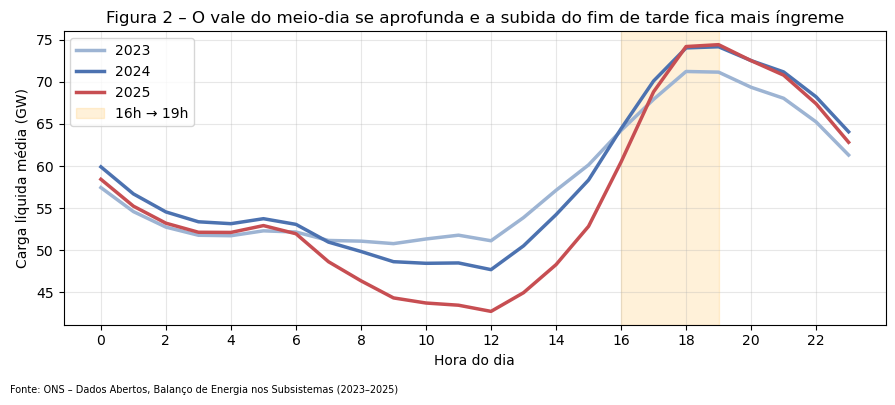

ano,2023,2024,2025
hora,,,
12,51.1,47.7,42.7
16,64.2,64.4,60.5
19,71.2,74.2,74.4


In [ ]:
# Calcula a média da carga líquida (em GW) para cada hora do dia e ano
cl_hora = sin.pivot_table(index='hora', columns='ano', values='carga_liquida') / 1000
#/1000 para representar em GW

# Desenha as curvas de cada ano
plt.figure(figsize=(9, 4))
for ano, cor in CORES.items():
    plt.plot(cl_hora.index, cl_hora[ano], color=cor, lw=2.5, label=ano)

# Destaca o período crítico do fim de tarde e ajusta os textos do gráfico
plt.axvspan(16, 19, color='orange', alpha=0.15, label='16h → 19h')
plt.title('Figura 2 – O vale do meio-dia se aprofunda e a subida do fim de tarde fica mais íngreme')
plt.xlabel('Hora do dia')
plt.ylabel('Carga líquida média (GW)')
plt.xticks(range(0, 24, 2))
plt.legend()
plt.grid(alpha=0.3)

# Ajusta o layout, adiciona a fonte e exibe o gráfico na tela
salvar('fig2_carga_liquida.png')

# Exibe o resumo apenas dos horários-chave: meio-dia, início e fim da rampa
display(cl_hora.loc[[12, 16, 19]].round(1))

**Resultado observado pelo gráfico e as médias de carga e geração solar:** a carga líquida do meio-dia cai a cada ano, enquanto a das 19h se mantém ou sobe. A distância entre o vale e o pico aumentou, tornando a subida do fim de tarde mais íngreme. **Aqui já podemos inferir** que, apesar da geração solar representar uma grande parcela da composição de geração para atendimento de carga do SIN, a sua saída representa um grande desafio. Enquando a carga continua crescendo, a saída com uma rampa cada vez mais ingrime representa mais recursos de geração controláveis disponíveis para atender a rampa de saída de geração  


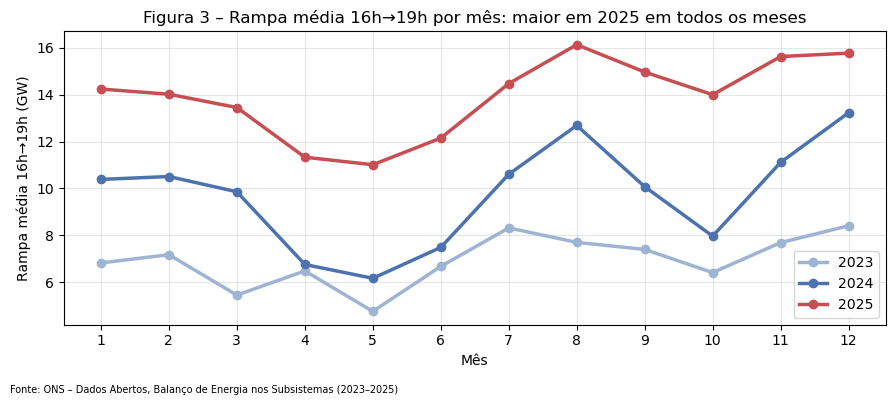

In [11]:
# Converte os valores mensais da rampa de MW para GW
rampa_mes_gw = rampa_mes / 1000

# Desenha a evolução mensal da rampa para cada ano
plt.figure(figsize=(9, 4))
for ano, cor in CORES.items():
    plt.plot(rampa_mes_gw.index, rampa_mes_gw[ano], marker='o', color=cor, lw=2.5, label=ano)

# Ajusta títulos, eixos, fonte no rodapé e exibe na tela
plt.title('Figura 3 – Rampa média 16h→19h por mês: maior em 2025 em todos os meses')
plt.xlabel('Mês')
plt.ylabel('Rampa média 16h→19h (GW)')
plt.xticks(range(1, 13))
plt.legend()
plt.grid(alpha=0.3)

salvar('fig3_rampa_mensal.png')

**Resultado observado pelas rampas:** a rampa média cresce a cada ano e é maior em 2025 em todos os meses.  o aumento não é efeito de um período específico do ano. 

**Rampa P95 (percentil 95 da rampa diária)** – anual e por mês, em GW.

In [12]:
# Percentil 95 (P95) da rampa diária 16h→19h, em GW: referência para os dias de rampa mais elevada
p95_ano = dia.groupby('ano')['rampa'].quantile(0.95) / 1000
p95_mes = dia.pivot_table(index='mes', columns='ano', values='rampa', aggfunc=lambda s: s.quantile(0.95)) / 1000

print('P95 anual da rampa (GW):')
display(p95_ano.to_frame('P95'))

print('\nP95 mensal da rampa (GW):')
display(p95_mes)

P95 anual da rampa (GW):


,P95
ano,
2023,15.3
2024,18.4
2025,22.7



P95 mensal da rampa (GW):


ano,2023,2024,2025
mes,,,
1,16.3,19.6,23.2
2,17.5,18.2,24.0
3,15.1,18.9,22.2
4,14.3,14.9,19.2
5,12.2,14.9,17.1
6,12.4,13.7,16.7
7,13.5,16.6,18.3
8,13.4,18.9,22.3
9,14.9,17.4,21.2


## 6. Análise estatística ou modelo
### 6.1 Método escolhido e justificativa
A pergunta é explicativa e a rampa é, por definição, a soma de três parcelas:

$$Rampa = {Carga} - {Eólica} + {Solar}$$

Para responder à pergunta "Como o crescimento da carga e o crescimento da geração solar se relacionam com a rampa da carga líquida no fim de tarde (16h→19h) do SIN entre 2023 e 2025, e qual dos dois deve orientar o dimensionamento do recurso controlável?", os dados analisados revelam o seguinte cenário:

Ritmos de crescimento desiguais: Entre 2023 e 2025, a carga média do SIN cresceu +8% (passando de cerca de 74 GW para 80 GW, um avanço médio próximo de 3 GW/ano), enquanto a geração solar média mais que dobrou, disparando +114% (saltando de aproximadamente 5 GW para mais de 10,7 GW, cerca de 2,8 GW/ano em geração média — o que representa picos muito maiores ao meio-dia).

O motor da rampa: Nesse mesmo período, a rampa média da carga líquida no fim de tarde (16h→19h) dobrou (+101%), saltando de ~7,0 GW para ~14,0 GW (+7,0 GW de aumento total). Ao decompor essa variação, fica claro que o simples aumento do consumo elétrico entre 16h e 19h responde por apenas 24% (+1,7 GW) do crescimento da rampa — valor praticamente anulado pela geração eólica no horário (−1,8 GW). Já a saída da geração solar ao pôr do sol explica 101% (+7,1 GW) de todo o aumento observado.

Conclusão: A saída rápida da geração solar no fim da tarde tem impacto direto e predominante sobre a necessidade de elevação das fontes controláveis (hidrelétricas e termelétricas). Portanto, é a expansão da geração solar — e não o crescimento tradicional da carga — que deve orientar o planejamento e o dimensionamento da reserva de potência flexível para atender à rampa diária do sistema.

### Como validar a afirmação anterior

### 6.2 Preparação e validação
As parcelas foram calculadas por dia e agregadas por ano. A validação consiste em conferir, no código, que a soma das parcelas é igual à rampa em todos os anos. Não há divisão treino/teste porque não há previsão, e não há risco de vazamento.

### 6.3 Resultados e interpretação
**Passo 1 – variação da carga ano a ano**

In [13]:
# 1. Cria uma tabela nova trazendo a carga média anual (em MWmed)
tab_carga = pd.DataFrame()
tab_carga['Carga média (MWmed)'] = medias['carga']

# 2. Calcula a diferença de um ano para o outro em megawatts (MW)
tab_carga['Variação (MW)'] = tab_carga['Carga média (MWmed)'].diff()

# 3. Calcula essa mesma diferença em percentual (%)
tab_carga['Variação (%)'] = tab_carga['Carga média (MWmed)'].pct_change() * 100

# 4. Exibe a tabela pronta na tela
display(tab_carga)

,Carga média (MWmed),Variação (MW),Variação (%)
ano,,,
2023,"73,705.0",NaN,NaN
2024,"78,943.3","5,238.3",7.1
2025,"79,608.9",665.7,0.8


**Passo 2 – crescimento da geração solar**

In [14]:
# 1. Cria uma tabela nova trazendo a geração solar média anual (em MWmed)
tab_solar = pd.DataFrame()
tab_solar['Solar média (MWmed)'] = medias['solar']

# 2. Calcula a diferença de um ano para o outro em megawatts (MW)
tab_solar['Variação (MW)'] = tab_solar['Solar média (MWmed)'].diff()

# 3. Calcula essa mesma diferença em percentual (%)
tab_solar['Variação (%)'] = tab_solar['Solar média (MWmed)'].pct_change() * 100

# 4. Exibe a tabela pronta na tela
display(tab_solar)

,Solar média (MWmed),Variação (MW),Variação (%)
ano,,,
2023,"4,909.7",NaN,NaN
2024,"8,349.6","3,439.9",70.1
2025,"10,483.2","2,133.5",25.6


**Passo 3 – carga × solar × rampa: (a) ritmo de crescimento**

,Carga,Solar,Rampa 16h→19h
ano,,,
2023,0.0,0.0,0.0
2024,7.0,70.0,41.0
2025,8.0,114.0,101.0


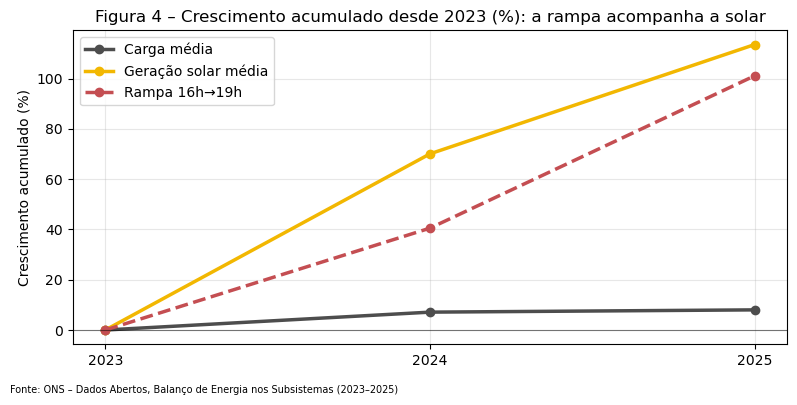

In [15]:
# Calcula o crescimento percentual acumulado em relação a 2023
crescimento_pct = (medias / medias.loc[2023] - 1) * 100
crescimento_pct.columns = ['Carga', 'Solar', 'Rampa 16h→19h']
display(crescimento_pct.round(0))

# Desenha as curvas de crescimento percentual
plt.figure(figsize=(8, 4))
estilos = {'Carga': ('o-', '#4D4D4D', 'Carga média'),
           'Solar': ('o-', '#F2B701', 'Geração solar média'),
           'Rampa 16h→19h': ('o--', '#C44E52', 'Rampa 16h→19h')}

for col, (estilo, cor, nome) in estilos.items():
    plt.plot(crescimento_pct.index, crescimento_pct[col], estilo, color=cor, lw=2.5, label=nome)

# Ajusta títulos, eixos, fonte no rodapé e exibe na tela
plt.title('Figura 4 – Crescimento acumulado desde 2023 (%): a rampa acompanha a solar')
plt.ylabel('Crescimento acumulado (%)')
plt.xticks([2023, 2024, 2025])
plt.axhline(0, color='black', lw=0.8, alpha=0.5)
plt.legend()
plt.grid(alpha=0.3)

salvar('fig4_crescimento.png')

**Passo 3 – (b) decomposição exata da rampa no fim de tarde**

In [16]:
# 1. Calcula a variação média no fim de tarde (16h→19h) por ano, já em GW
ft = dia.groupby('ano')[['d_carga', 'd_eolica', 'd_solar', 'rampa']].mean() / 1000

# 2. Separa cada parcela ajustando o sinal (quando solar ou eólica caem, elas puxam a rampa para cima)
parcelas = pd.DataFrame()
parcelas['Subida da carga']     = ft['d_carga']
parcelas['Variação eólica (−)'] = -ft['d_eolica']
parcelas['Saída da solar']      = -ft['d_solar']
parcelas['Rampa']               = ft['rampa']

# 3. Prova que a conta fecha: soma as três parcelas e compara com a rampa total
soma_parcelas = parcelas['Subida da carga'] + parcelas['Variação eólica (−)'] + parcelas['Saída da solar']
diferenca = (soma_parcelas - parcelas['Rampa']).abs().max()
print(f'Conferência da conta: diferença máxima entre a soma e a rampa = {diferenca:.4f} GW (conta fechada!)')

# 4. Monta a tabela final colocando as parcelas nas linhas e comparando 2023 com 2025
tabela = pd.DataFrame({
    '2023 (GW)': parcelas.loc[2023],
    '2025 (GW)': parcelas.loc[2025]
})

# Calcula o aumento em GW e o peso (%) de cada parcela no crescimento total da rampa
tabela['Aumento (GW)'] = tabela['2025 (GW)'] - tabela['2023 (GW)']
aumento_total_rampa    = tabela.loc['Rampa', 'Aumento (GW)']
tabela['% do aumento da rampa'] = (tabela['Aumento (GW)'] / aumento_total_rampa) * 100

tabela.index.name = 'Parcela (média 16h→19h)'
display(tabela.round(1))

Conferência da conta: diferença máxima entre a soma e a rampa = 0.0000 GW (conta fechada!)


,2023 (GW),2025 (GW),Aumento (GW),% do aumento da rampa
Parcela (média 16h→19h),,,,
Subida da carga,4.0,5.7,1.7,24.4
Variação eólica (−),-2.5,-4.2,-1.8,-25.3
Saída da solar,5.4,12.5,7.1,100.9
Rampa,6.9,13.9,7.0,100.0


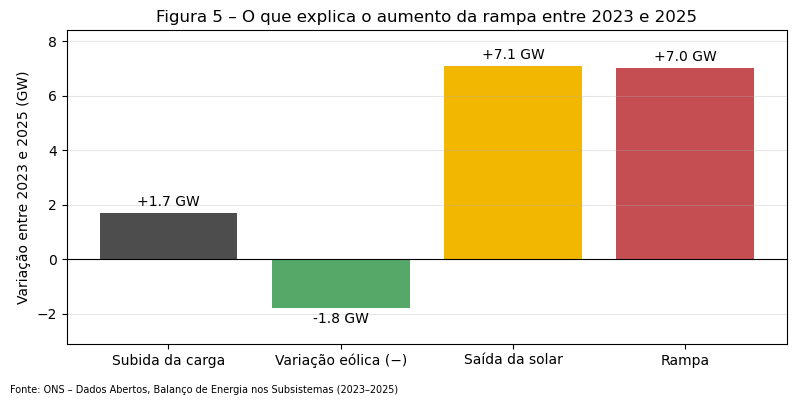

In [27]:
# Desenha as barras mostrando o quanto cada fator contribuiu para o aumento da rampa
plt.figure(figsize=(8, 4))
cores = ['#4D4D4D', '#55A868', '#F2B701', '#C44E52']
barras = plt.bar(tabela.index, tabela['Aumento (GW)'], color=cores)
plt.bar_label(barras, fmt='%+.1f GW', padding=3)

# Ajusta linha de base, título, fonte no rodapé e exibe na tela
plt.axhline(0, color='black', lw=0.8)
plt.title('Figura 5 – O que explica o aumento da rampa entre 2023 e 2025')
plt.ylabel('Variação entre 2023 e 2025 (GW)')
plt.margins(y=0.15)
plt.grid(alpha=0.3, axis='y')

salvar('fig5_decomposicao.png')

In [18]:
# 1. Busca o crescimento acumulado (%) entre 2023 e 2025 na tabela de crescimento
var_carga = crescimento_pct.loc[2025, 'Carga']
var_solar = crescimento_pct.loc[2025, 'Solar']
var_rampa = crescimento_pct.loc[2025, 'Rampa 16h→19h']

# 2. Busca quanto cada fator explica (%) do aumento da rampa na tabela de parcelas
peso_carga = tabela.loc['Subida da carga', '% do aumento da rampa']
peso_solar = tabela.loc['Saída da solar', '% do aumento da rampa']

# 3. Exibe o resumo final das conclusões na tela
print(f"Entre 2023 e 2025: carga {var_carga:+.0f}% | solar {var_solar:+.0f}% | rampa {var_rampa:+.0f}%")
print(f"Aumento da rampa explicado pela subida da carga: {peso_carga:.0f}%")
print(f"Aumento da rampa explicado pela saída da solar:  {peso_solar:.0f}%")

Entre 2023 e 2025: carga +8% | solar +114% | rampa +101%
Aumento da rampa explicado pela subida da carga: 24%
Aumento da rampa explicado pela saída da solar:  101%


**Resultado observado:** a carga cresceu cerca de 8%, enquanto a rampa cresceu cerca de 101%, ritmo próximo ao da solar. No fim de tarde, o aumento da subida da carga (+1,7 GW) foi compensado pela eólica (−1,8 GW), e a saída da solar (+7,1 GW) explica praticamente todo o aumento da rampa.  
**Interpretação:** **a rampa não acompanha o crescimento da carga, e sim a saída da geração solar.**  
**Limitação:** a decomposição é contábil e descritiva, sem teste formal de significância, e com apenas três anos.

**Como a rampa foi suprida (despacho no fim de tarde).** Variação média de cada fonte entre 16h e 19h (positivo = a fonte aumentou geração).

,d_solar,d_eolica,d_hidro,d_termica,rampa,% hidráulica,% térmica
ano,,,,,,,
2023,-5.4,2.5,6.8,0.1,6.9,98.8,2.0
2024,-9.4,3.0,9.1,0.4,9.7,93.8,4.0
2025,-12.5,4.2,13.7,0.2,13.9,98.2,1.7


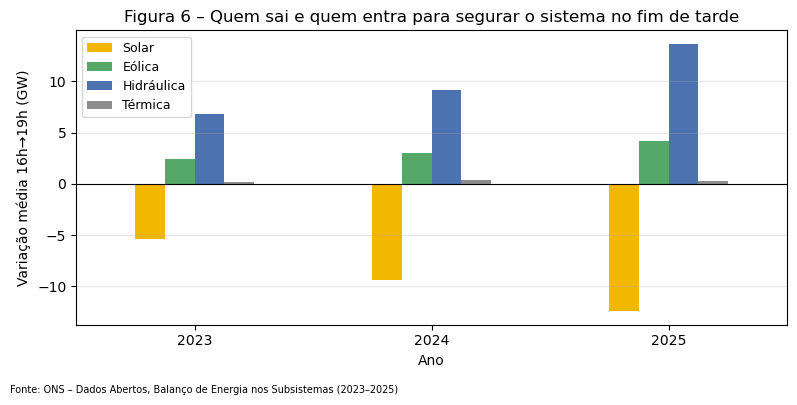

In [19]:
# Calcula a variação média de cada fonte no fim de tarde (16h→19h), já em GW
sup = dia.groupby('ano')[['d_solar', 'd_eolica', 'd_hidro', 'd_termica', 'rampa']].mean() / 1000
sup['% hidráulica'] = (sup['d_hidro'] / sup['rampa']) * 100
sup['% térmica']    = (sup['d_termica'] / sup['rampa']) * 100
display(sup.round(1))

# Desenha as barras agrupadas mostrando quem sai e quem entra no fim de tarde
fontes_gw = sup[['d_solar', 'd_eolica', 'd_hidro', 'd_termica']].set_axis(['Solar', 'Eólica', 'Hidráulica', 'Térmica'], axis=1)
fontes_gw.plot(kind='bar', figsize=(8, 4), color=['#F2B701', '#55A868', '#4C72B0', '#8C8C8C'])

# Ajusta linha de base, título, fonte no rodapé e exibe na tela
plt.axhline(0, color='black', lw=0.8)
plt.title('Figura 6 – Quem sai e quem entra para segurar o sistema no fim de tarde')
plt.ylabel('Variação média 16h→19h (GW)')
plt.xlabel('Ano')
plt.xticks(rotation=0)
plt.legend(fontsize=9)
plt.grid(alpha=0.3, axis='y')

salvar('fig6_suprimento.png')

As tabelas e o gráfico mostram quanto as usinas hidráulicas e térmicas tem um despacho acelerado entre 16h e 19h em cada ano, revelando quem efetivamente assumiu a reposição da energia solar no fim de tarde — com a pequena diferença restante entre a soma dessas fontes e a rampa total correspondendo ao intercâmbio internacional e a outras parcelas não detalhadas na base.

## 7. Resposta à pergunta
Entre 2023 e 2025, a rampa de fim de tarde da carga líquida do SIN dobrou — saltando de cerca de 7 GW para 14 GW em apenas três horas —, enquanto a carga cresceu apenas 8%. Na prática, os números mostram que a rampa diária não acompanha o ritmo da carga, mas sim a saída da geração solar ao pôr do sol, que explica praticamente 100% desse aumento. Por isso, o planejamento de potência controlável para o fim da tarde precisa olhar diretamente para a expansão solar, e não apenas para o crescimento tradicional da demanda.

O que fazer na prática?
Planejar pela curva solar: Como a saída do sol ao fim do dia dita o tamanho da rampa, a expansão fotovoltaica precisa entrar diretamente na conta que dimensiona as usinas flexíveis (hidrelétricas e termelétricas).

Garantir folga de modulação entre 16h e 19h: Como são as hidrelétricas e termelétricas que seguram a queda solar nesse horário, a programação diária precisa assegurar que essas máquinas tenham margem disponível para subir potência rapidamente.

## 8. Reprodutibilidade e organização
Este projeto foi desenvolvido em Python (3.10+) no Jupyter Notebook (VS Code) utilizando apenas as bibliotecas pandas e matplotlib, com leitura via caminhos relativos na mesma pasta do projeto (`Projeto Integrador - Felipe Damasceno/`, bases públicas do ONS). Para rodar tudo do zero e gerar novamente os gráficos e tabelas, basta instalar as dependências listadas em requirements.txt, reiniciar o kernel e executar todas as células em sequência no arquivo FelipeDamasceno_ProjetoIntegrador.ipynb.

## 9. Referências e fontes externas
- ONS – Portal de Dados Abertos: *Balanço de Energia nos Subsistemas* e dicionário de dados.
- ONS – Procedimentos de Rede, Submódulo 1.2 – Glossário (rev. 2025.02).
- Guia, Template e Plano da Oficina do Projeto Integrador – Módulo Analytics.
- Documentação oficial de pandas e matplotlib.
- Código desenvolvido pelo participante, com apoio do Microsoft Copilot na estruturação.

## 10. Checklist do participante
- [ ] A pergunta está explícita e alinhada ao objetivo.
- [ ] A descrição da base permite compreender o que cada registro representa.
- [ ] Todos os tratamentos foram justificados.
- [ ] As análises e os gráficos contribuem para responder à pergunta.
- [ ] O método utilizado é compatível com os dados e com o objetivo.
- [ ] As conclusões são proporcionais às evidências.
- [ ] As limitações e os próximos passos foram registrados.
- [ ] O notebook executa integralmente.
- [ ] Os arquivos estão organizados, as fontes foram identificadas e o projeto é compreensível sem explicações orais.